In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
from plot_utils_and_functions import *

In [3]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
beta = 4.5
delta = 0.3
n_special = 30
t_transient = 200
tmax = 1200
eta_special = 1
beta_special = 4.5
delta_special = 0.3

In [4]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

In [5]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [6]:
n_sim = 10

In [7]:
simulation = False

if simulation:
    all_positions = np.zeros((tmax-t_transient, n+n_special, 2))
    all_pheromones = np.zeros((tmax-t_transient, Lx, Ly))

    for sim in range(n_sim):
        for beta in beta_list:
            for delta in delta_list:
                print(f"Testing with delta = {delta}, beta = {beta}")

                env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        beta, delta, tmax, n_special, t_transient) # in this case beta, delta are beta and delta also for special ants
                
                env.reset_objects()
                env.transient()
                
                for t in range(tmax-t_transient):
                    env.update()
                    all_positions[t, :, :] = env.positions.copy()
                    all_pheromones[t, :, :] = env.pheromones.copy()

                all_positions = np.array(all_positions)
                all_pheromones = np.array(all_pheromones)
                np.savez(f"entropy/test_results_delta_{delta}_beta_{beta}_enh_{sim}.npz", all_positions=all_positions, all_pheromones=all_pheromones)

In [8]:
policies = [i for i in range(n_sim)]
beta = beta_list
delta = delta_list

In [9]:
L = 32  # Dimensione della griglia / box

# 1. Definisci qui la tua lista di lag desiderati
lag_list = [1, 2, 5, 10, 20, 32, 50, 60]
num_lags = len(lag_list)

# Matrici di supporto per i risultati
collective_entropy_results = np.zeros((len(policies), len(beta), len(delta)))
individual_entropy_results = np.zeros((len(policies), len(beta), len(delta)))
individual_entropy_std_results = np.zeros((len(policies), len(beta), len(delta)))
mutual_info_results = np.zeros((len(policies), len(beta), len(delta)))

# Nuove misure (allocate con la dimensione num_lags)
extent_results = np.zeros((len(policies), len(beta), len(delta)))
msd_results = np.zeros((len(policies), len(beta), len(delta), num_lags))
persistence_results = np.zeros((len(policies), len(beta), len(delta), num_lags))

tau = 100  # Ultimi 100 time step

for sim in policies:
    for b in beta:
        for d in delta:

            # 1. Carica il file .npz
            filename = f"entropy/test_results_delta_{d}_beta_{b}_enh_{sim}.npz"
            data = np.load(filename)
            pos = data['all_positions']  # Shape: (1000, 330, 2)
    
            # 2. Ultimi tau time step e primi n individui
            pos_last_tau = pos[-tau:, :n]  # Shape: (tau, num_ants, 2)
            num_timesteps, num_ants, _ = pos_last_tau.shape
    
            # -------------------------------------------------------------
            # A. ENTROPIA, MUTUAL INFORMATION ED ESTENSIONE SPAZIALE (E)
            # -------------------------------------------------------------
            flat_pos = pos_last_tau.reshape(-1, 2)
            _, inverse_indices = np.unique(flat_pos, axis=0, return_inverse=True)
            cell_ids = inverse_indices.reshape(num_timesteps, num_ants)
            num_cells = np.max(cell_ids) + 1  # Numero totale di celle uniche visitate
                
            p_ik = np.zeros((num_cells, num_ants))
            for k in range(num_ants):
                p_ik[:, k] = np.bincount(cell_ids[:, k], minlength=num_cells) / num_timesteps
    
            with np.errstate(divide='ignore', invalid='ignore'):
                log2_p_ik = np.where(p_ik > 0, np.log2(p_ik), 0.0)
                individual_entropies = -np.sum(p_ik * log2_p_ik, axis=0)

            p_i = np.mean(p_ik, axis=1)
            with np.errstate(divide='ignore', invalid='ignore'):
                log2_p_i = np.where(p_i > 0, np.log2(p_i), 0.0)
                h_coll = -np.sum(p_i * log2_p_i)

            h_ind = np.mean(individual_entropies)
            mutual_info = h_coll - h_ind

            # Estensione spaziale E: celle uniche visitate da ogni formica in finestra T
            E_k = np.array([len(np.unique(pos_last_tau[:, k, :], axis=0)) for k in range(num_ants)])
            E = np.mean(E_k)

            # -------------------------------------------------------------
            # B. PBC, UNWRAPPING, MSD(l) E PERSISTENZA DIREZIONALE C(l)
            # -------------------------------------------------------------
            # 1. Spostamenti passo-passo raw
            dx = np.diff(pos_last_tau, axis=0)  # Shape: (tau-1, num_ants, 2)
            
            # 2. Correzione PBC per gli spostamenti passo-passo
            dx_pbc = dx - L * np.round(dx / L)
            
            # 3. Traiettoria srotolata (Unwrapped) per il calcolo corretto di MSD
            pos_unwrap = np.zeros_like(pos_last_tau)
            pos_unwrap[0] = pos_last_tau[0]
            pos_unwrap[1:] = pos_last_tau[0] + np.cumsum(dx_pbc, axis=0)

            # 4. Calcolo dei vettori unitari di direzione u_k(t)
            step_norms = np.linalg.norm(dx_pbc, axis=-1, keepdims=True)
            u_k = np.where(step_norms > 1e-8, dx_pbc / step_norms, 0.0)  # Shape: (tau-1, num_ants, 2)

            # 5. Calcolo di MSD(l) e C(l) iterando direttamente su lag_list
            msd_l = np.zeros(num_lags)
            c_l = np.zeros(num_lags)

            for idx, lag in enumerate(lag_list):
                # MSD: spostamento srotolato al tempo (t + lag) rispetto a t
                if lag < tau:
                    disp = pos_unwrap[lag:] - pos_unwrap[:-lag]  # (tau - lag, num_ants, 2)
                    msd_l[idx] = np.mean(np.sqrt(np.sum(disp**2, axis=-1)))
                else:
                    msd_l[idx] = np.nan

                # C(l): Prodotto scalare tra vettori direzione distanziati di 'lag'
                if lag < len(u_k):  # len(u_k) è tau - 1
                    u_t = u_k[:-lag]
                    u_t_lag = u_k[lag:]
                    dot_products = np.sum(u_t * u_t_lag, axis=-1)  # (tau - 1 - lag, num_ants)
                    c_l[idx] = np.mean(dot_products)
                else:
                    c_l[idx] = np.nan

            # -------------------------------------------------------------
            # C. SALVATAGGIO DEI RISULTATI
            # -------------------------------------------------------------
            bi, di = beta.index(b), delta.index(d)

            collective_entropy_results[sim, bi, di] = h_coll/np.log2(L**2)  # Normalizzazione
            individual_entropy_results[sim, bi, di] = h_ind
            individual_entropy_std_results[sim, bi, di] = np.std(individual_entropies)
            mutual_info_results[sim, bi, di] = mutual_info
            extent_results[sim, bi, di] = E
            msd_results[sim, bi, di, :] = msd_l
            persistence_results[sim, bi, di, :] = c_l

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244337/523156693.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

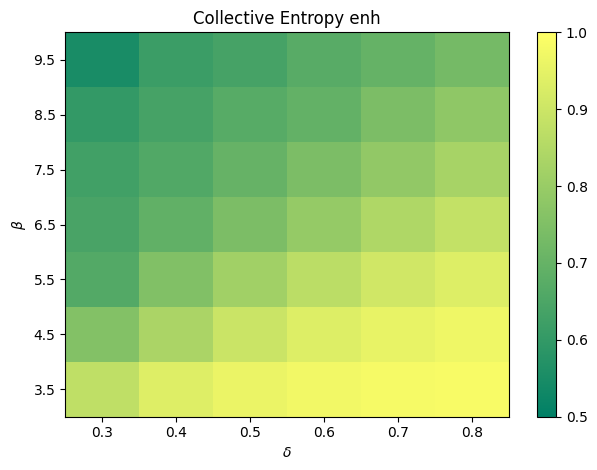

In [10]:
plt.figure(figsize=(8, 6))
entropy_results = np.mean(collective_entropy_results, axis=0)  # Media su tutte le simulazioni
'''plt.imshow(entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='summer', vmin=0.5, vmax=1)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')'''

plot_heatmap(entropy_results, delta_list, beta_list,
              title='Collective Entropy enh', cmap='summer', vmin=0.5, vmax=1)

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244337/287042072.py:6: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

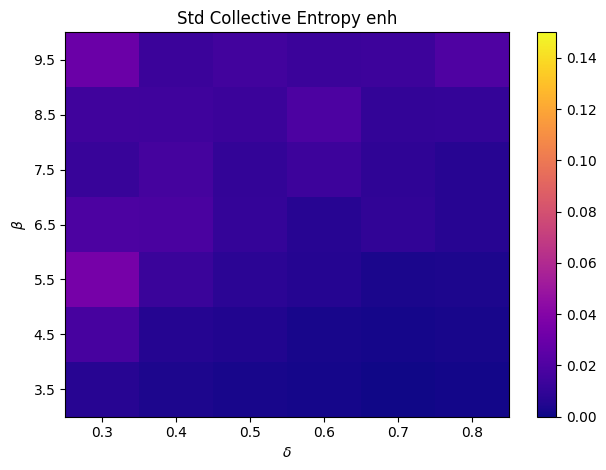

In [11]:
plt.figure(figsize=(8, 6))
std_entropy_results = np.std(collective_entropy_results, axis=0)  # Media su tutte le simulazioni
'''plt.imshow(std_entropy_results, origin='lower', extent=[min(delta_list), max(delta_list), min(beta_list), max(beta_list)],
            aspect='auto', cmap='plasma')#, vmin=0.5, vmax=1)
plt.colorbar(label=r'${std(H)}$')
plt.xlabel(r'$\delta$')  
plt.ylabel(r'$\beta$')'''

plot_heatmap(std_entropy_results, delta_list, beta_list,
              title='Std Collective Entropy enh', cmap='plasma', vmin=0.0, vmax=0.15)

<>:16: SyntaxWarning: invalid escape sequence '\d'
<>:16: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244337/4136194559.py:16: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

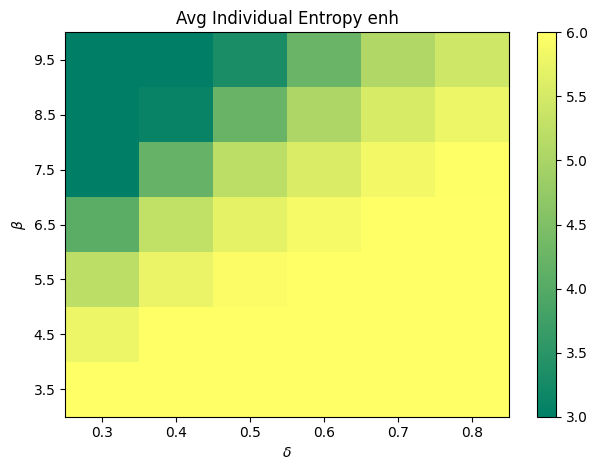

In [12]:
plt.figure(figsize=(8, 6))
avg_entropy = individual_entropy_results.mean(axis=0)  # Media su tutte le simulazioni  
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    avg_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='summer',
    vmin=3,
    vmax=6
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')'''

plot_heatmap(avg_entropy, delta_list, beta_list,
              title='Avg Individual Entropy enh', cmap='summer', vmin=3, vmax=6)

<>:14: SyntaxWarning: invalid escape sequence '\d'
<>:14: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244337/1568256256.py:14: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


<Figure size 800x600 with 0 Axes>

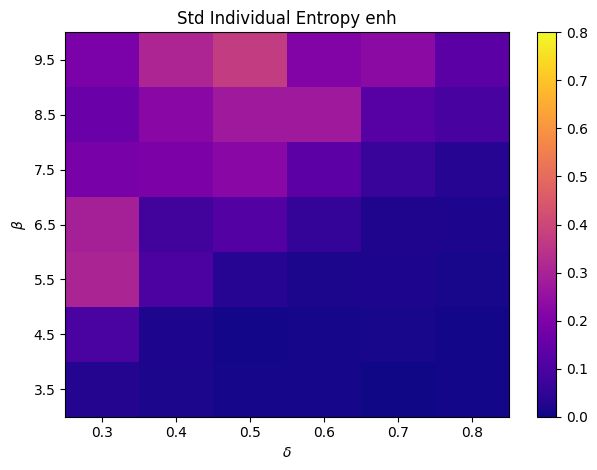

In [17]:
plt.figure(figsize=(8, 6))
std_entropy = individual_entropy_results.std(axis=0)  # Media su tutte le simulazioni  
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.imshow(
    std_entropy,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='plasma'
)
plt.colorbar(label=r'${H}$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')'''

plot_heatmap(std_entropy, delta_list, beta_list,
              title='Std Individual Entropy enh', cmap='plasma', vmin=0.0, vmax=0.8)

<>:21: SyntaxWarning: invalid escape sequence '\d'
<>:21: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244337/2226199389.py:21: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


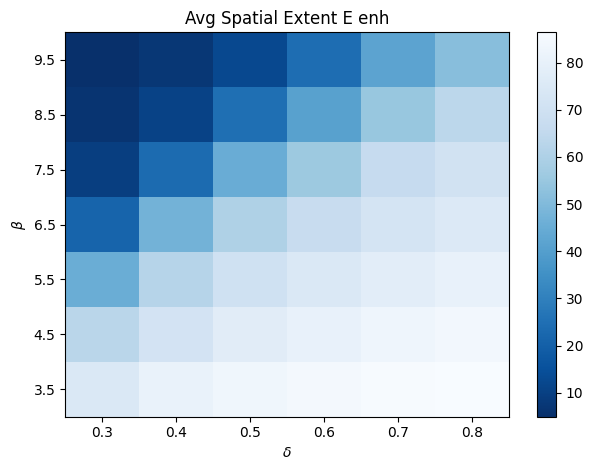

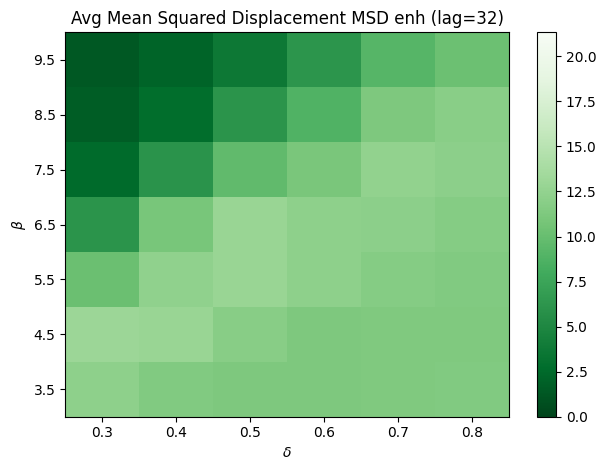

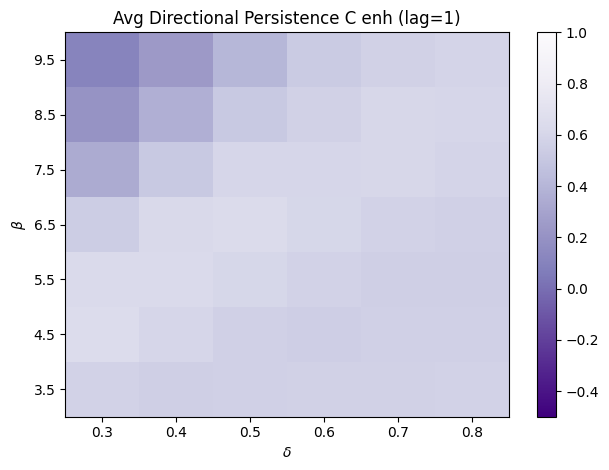

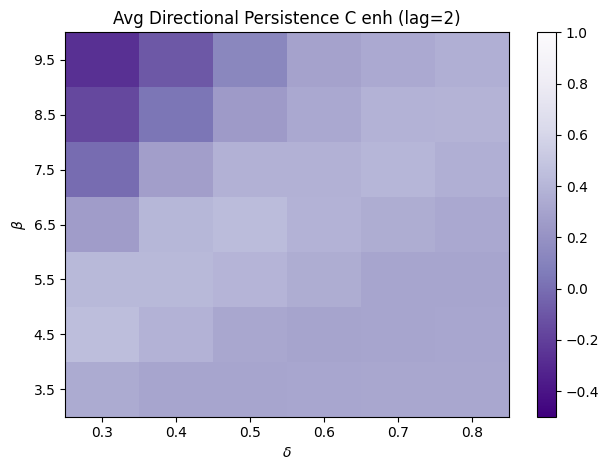

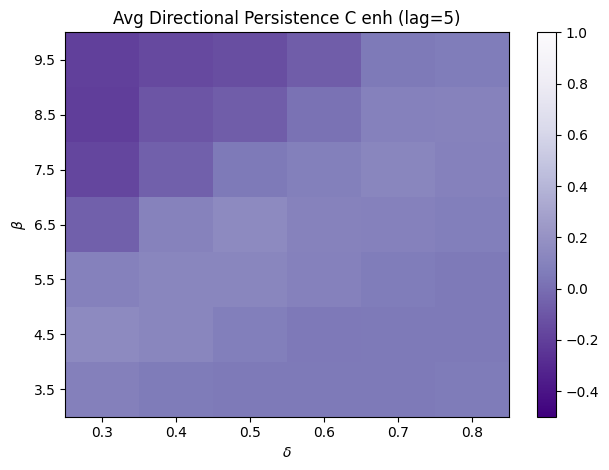

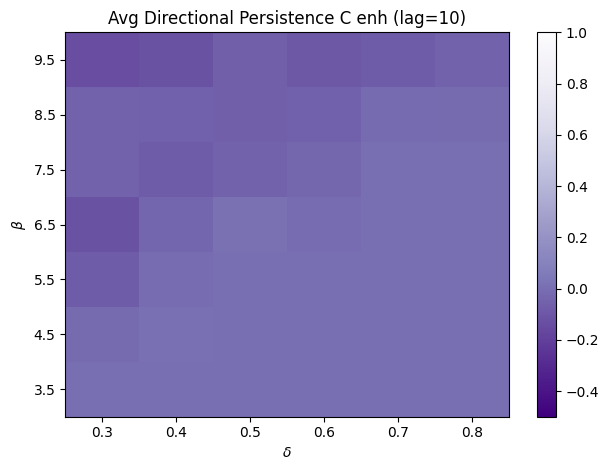

In [14]:
# 1. Media dell'Informazione Mutua lungo le simulazioni (axis=0)
avg_extent_results = np.mean(extent_results, axis=0)
avg_msd_results = np.mean(msd_results, axis=0)
avg_persistence_results = np.mean(persistence_results, axis=0)
chosen_lag = 32  # Lag scelto per visualizzare MSD(l) e C(l)
index_of_chosen_lag = lag_list.index(chosen_lag)  # Ottieni l'indice del lag scelto
lags_for_directional_persistence = [1,2,5,10]
'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_extent_results,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Blues_r'
)
plt.colorbar(label=r'$E$')

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Spatial Extent $E$ enh')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_msd_results[:,:,index_of_chosen_lag],  # Visualizza MSD al lag scelto
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Greens_r',
    vmin=0, vmax=chosen_lag*2/3
)
plt.colorbar(label=r'$MSD(l)$')  # Aggiunta della barra del colore per MSD

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Mean Squared Displacement $MSD(l)$ enh')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(
    avg_persistence_results[:,:,index_of_chosen_lag],  # Visualizza C(l) al lag scelto
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Purples_r'
)
plt.colorbar(label=r'$C(l)$')  # Aggiunta della barra del colore per C(l)

plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Average Directional Persistence $C(l)$ enh')
plt.tight_layout()
plt.show()'''

plot_heatmap(avg_extent_results, delta_list, beta_list,
              title='Avg Spatial Extent E enh', cmap='Blues_r')
plot_heatmap(avg_msd_results[:,:,index_of_chosen_lag], delta_list, beta_list,
              title=f'Avg Mean Squared Displacement MSD enh (lag={chosen_lag})', cmap='Greens_r', vmin=0, vmax=chosen_lag*2/3)

for lag_for_directional_persistence in lags_for_directional_persistence:
    index_of_lag_for_directional_persistence = lag_list.index(lag_for_directional_persistence)  # Ottieni l'indice del lag scelto per la persistenza direz
    plot_heatmap(avg_persistence_results[:,:,index_of_lag_for_directional_persistence], delta_list, beta_list,
              title=f'Avg Directional Persistence C enh (lag={lag_for_directional_persistence})', cmap='Purples_r',
                vmin=-0.5, vmax=1)

<>:20: SyntaxWarning: invalid escape sequence '\d'
<>:20: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_244337/2408805753.py:20: SyntaxWarning: invalid escape sequence '\d'
  plt.xlabel(r'$\delta$')


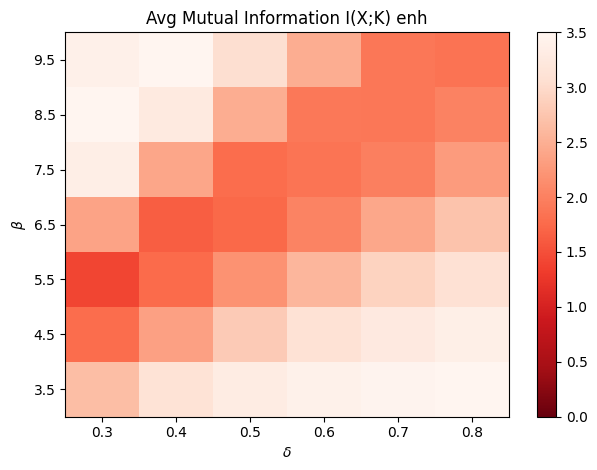

In [15]:
# 1. Media dell'Informazione Mutua lungo le simulazioni (axis=0)
avg_mutual_info = np.mean(mutual_info_results, axis=0)

'''xmin, xmax = min(delta), max(delta)
ymin, ymax = min(beta), max(beta)

# 2. Creazione della figura
plt.figure(figsize=(8, 6))
plt.imshow(
    avg_mutual_info,
    origin='lower',
    extent=[xmin, xmax, ymin, ymax],
    aspect='auto',
    cmap='Reds_r',  # 'viridis' o 'plasma' mettono in risalto i valori di informazione mutua; puoi usare 'summer' se preferisci la stessa palette
    vmin=0,        # scommenta e imposta se vuoi fissare la scala minima
    vmax=3.5        # scommenta e imposta se vuoi fissare la scala massima
)

plt.colorbar(label=r'$I(X; K)$')
plt.xlabel(r'$\delta$')
plt.ylabel(r'$\beta$')
plt.title(r'Mutual Information $I(X; K)$ enh')
plt.tight_layout()
plt.show()'''

plot_heatmap(avg_mutual_info, delta_list, beta_list,
              title='Avg Mutual Information I(X;K) enh', cmap='Reds_r', vmin=0, vmax=3.5)

In [16]:
# Liste dei valori desiderati nelle righe e colonne della tabella
beta_target = [9.5, 8.5, 7.5, 6.5, 5.5, 4.5, 3.5]
delta_target = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

# Esempio d'uso:
print_latex_block(entropy_results, avg_entropy, beta_list, delta_list)

9.5 & 0.55 & 0.62 & 0.64 & 0.67 & 0.70 & 0.73 & 2.09 & 2.57 & 3.31 & 4.25 & 5.08 & 5.44 \\
8.5 & 0.60 & 0.64 & 0.67 & 0.69 & 0.74 & 0.78 & 2.39 & 3.10 & 4.22 & 5.04 & 5.53 & 5.78 \\
7.5 & 0.63 & 0.66 & 0.70 & 0.74 & 0.79 & 0.83 & 2.92 & 4.20 & 5.21 & 5.56 & 5.86 & 5.98 \\
6.5 & 0.64 & 0.69 & 0.74 & 0.79 & 0.84 & 0.88 & 4.08 & 5.27 & 5.69 & 5.89 & 6.01 & 6.10 \\
5.5 & 0.66 & 0.75 & 0.81 & 0.87 & 0.91 & 0.93 & 5.21 & 5.75 & 5.96 & 6.07 & 6.16 & 6.22 \\
4.5 & 0.76 & 0.83 & 0.89 & 0.93 & 0.95 & 0.97 & 5.78 & 6.00 & 6.14 & 6.21 & 6.28 & 6.31 \\
3.5 & 0.87 & 0.93 & 0.96 & 0.97 & 0.98 & 0.99 & 6.07 & 6.22 & 6.29 & 6.32 & 6.35 & 6.36 \\
